In [1]:
import os, sys, time
from pathlib import Path
PROJECT = Path(r"C:\Users\hp\Documents\teliport_prototype")
os.chdir(PROJECT / "notebooks")
sys.path.insert(0, str(PROJECT / "src"))
%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from cmapss_data import SUBSETS

PROC = PROJECT / "data" / "processed"
MODELS = PROJECT / "models"
REPORTS = PROJECT / "reports"
FIG_DIR = REPORTS / "figures"
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("Working dir:", Path.cwd())

Working dir: C:\Users\hp\Documents\teliport_prototype\notebooks


In [2]:
%%writefile ../src/anomaly.py
"""Unsupervised degradation (anomaly) detection for C-MAPSS.

Learns what a HEALTHY engine looks like (rows far from failure) and scores how far each
reading has drifted from it. Uses the "drift from own early-life baseline" features, so
deviation in ANY direction counts -> works for both fault modes (FD003/FD004) without labels.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest

HEALTHY_RUL = 125      # same boundary as the RUL cap: > 125 cycles from failure = healthy

SENSOR_NAMES = {
    "s2": "LPC outlet temperature (T24)", "s3": "HPC outlet temperature (T30)",
    "s4": "LPT outlet temperature (T50)", "s7": "HPC outlet pressure (P30)",
    "s8": "Fan speed (Nf)", "s9": "Core speed (Nc)",
    "s11": "HPC static pressure (Ps30)", "s12": "Fuel flow / Ps30 ratio (phi)",
    "s13": "Corrected fan speed (NRf)", "s14": "Corrected core speed (NRc)",
    "s15": "Bypass ratio (BPR)", "s17": "Bleed enthalpy (htBleed)",
    "s20": "HPT coolant bleed (W31)", "s21": "LPT coolant bleed (W32)",
}


class HealthMonitor:
    def __init__(self, method="mahalanobis", suffix="_dbase", quantile=0.99,
                 persistence=5, healthy_rul=HEALTHY_RUL, random_state=42):
        self.method = method
        self.suffix = suffix
        self.quantile = quantile
        self.persistence = persistence
        self.healthy_rul = healthy_rul
        self.random_state = random_state

    def _X(self, df):
        return df[self.features_].to_numpy(dtype=float)

    def _raw_score(self, X):
        if self.method == "mahalanobis":
            d = X - self.cov_.location_
            return np.einsum("ij,jk,ik->i", d, self.cov_.precision_, d)
        return -self.iforest_.score_samples(X)

    def fit(self, df, sensors):
        self.sensors_ = list(sensors)
        self.features_ = [f"{s}{self.suffix}" for s in self.sensors_]
        X = self._X(df[df["RUL"] > self.healthy_rul])          # healthy rows only
        if self.method == "mahalanobis":
            self.cov_ = LedoitWolf().fit(X)
        else:
            self.iforest_ = IsolationForest(n_estimators=300, random_state=self.random_state).fit(X)
        self.threshold_ = float(np.quantile(self._raw_score(X), self.quantile))
        return self

    def transform(self, df):
        """anomaly_score > 1 = outside the healthy envelope; alarm = score > 1 for k cycles in a row."""
        out = df[["unit", "cycle"]].copy()
        out["anomaly_score"] = self._raw_score(self._X(df)) / self.threshold_
        raw = (out["anomaly_score"] > 1.0).astype(int)
        streak = raw.groupby(out["unit"]).rolling(self.persistence, min_periods=self.persistence).sum()
        out["alarm"] = streak.reset_index(level=0, drop=True).reindex(out.index).fillna(0) >= self.persistence
        return out

    def top_contributors(self, row, n=3):
        """Which sensors push this reading out of the healthy envelope (Mahalanobis only)."""
        d = np.asarray(row[self.features_], dtype=float) - self.cov_.location_
        contrib = np.clip(d * (self.cov_.precision_ @ d), 0, None)
        share = contrib / max(contrib.sum(), 1e-9)
        order = np.argsort(contrib)[::-1][:n]
        return [(self.sensors_[i], SENSOR_NAMES.get(self.sensors_[i], self.sensors_[i]),
                 round(float(100 * share[i]), 1)) for i in order]


def detection_report(df, flags, healthy_rul=HEALTHY_RUL, critical=30):
    """Lead time and false alarms, measured on run-to-failure engines."""
    m = df[["unit", "cycle", "RUL"]].join(flags[["anomaly_score", "alarm"]])
    healthy = m[m["RUL"] > healthy_rul]
    first = m[m["alarm"]].groupby("unit")["RUL"].max()           # RUL when the first alarm fired
    n_units = m["unit"].nunique()
    true_alarms = first[first <= healthy_rul]
    return {
        "engines": int(n_units),
        "false_alarm_rate_%": round(float(100 * healthy["alarm"].mean()), 2),
        "engines_with_early_alarm_%": round(float(100 * (first > healthy_rul).sum() / n_units), 1),
        "detected_before_failure_%": round(float(100 * m.groupby("unit")["alarm"].any().mean()), 1),
        f"detected_before_RUL{critical}_%": round(float(100 * (first > critical).sum() / n_units), 1),
        "median_lead_time_cycles": float(true_alarms.median()) if len(true_alarms) else np.nan,
    }

Writing ../src/anomaly.py


In [3]:
from anomaly import HealthMonitor, detection_report

rows, oof_flags = [], {}
for fd in SUBSETS:
    tr = pd.read_pickle(PROC / f"train_{fd}.pkl")
    S = joblib.load(MODELS / f"preprocessor_{fd}.joblib").sensors
    for method in ("mahalanobis", "iforest"):
        parts = []
        for a, b in GroupKFold(n_splits=4).split(tr, groups=tr["unit"]):
            hm = HealthMonitor(method=method).fit(tr.iloc[a], S)
            parts.append(hm.transform(tr.iloc[b]))
        flags = pd.concat(parts).loc[tr.index]
        if method == "mahalanobis":
            oof_flags[fd] = flags
        rows.append({"subset": fd, "method": method, **detection_report(tr, flags)})

cmp_table = pd.DataFrame(rows).set_index(["subset", "method"])
cmp_table.to_csv(REPORTS / "anomaly_cv_comparison.csv")
cmp_table

engines  false_alarm_rate_%  engines_with_early_alarm_%  detected_before_failure_%  detected_before_RUL30_%  median_lead_time_cycles
subset method                                                                                                                                           
FD001  mahalanobis      100                1.08                         7.0                      100.0                    100.0                     77.0
       iforest          100                0.70                         4.0                      100.0                    100.0                     66.5
FD002  mahalanobis      260                0.50                         4.6                      100.0                     99.6                     66.0
       iforest          260                0.65                         3.5                      100.0                     98.5                     64.0
FD003  mahalanobis      100                2.91                         6.0                      100.0                    100.0                     71.5
       iforest          100                0.97                         3.0                      100.0                     93.0                     53.0
FD004  mahalanobis      249                0.96                         4.8                      100.0                     98.0                     64.0
       iforest          249                0.99                         4.4                      100.0                     90.0                     61.0

In [4]:
pred_df = pd.read_csv(REPORTS / "test_predictions_lgbm.csv")
status = []
for fd in SUBSETS:
    tr = pd.read_pickle(PROC / f"train_{fd}.pkl")
    te = pd.read_pickle(PROC / f"test_{fd}.pkl")
    S = joblib.load(MODELS / f"preprocessor_{fd}.joblib").sensors
    hm = HealthMonitor(method="mahalanobis").fit(tr, S)
    joblib.dump(hm, MODELS / f"health_monitor_{fd}.joblib")
    fl = hm.transform(te)
    last = fl.groupby("unit").tail(1)[["unit", "anomaly_score", "alarm"]]
    status.append(last.assign(subset=fd))

status = pd.concat(status, ignore_index=True)
test_status = pred_df.merge(status, on=["subset", "unit"])
test_status.to_csv(REPORTS / "test_status.csv", index=False)

bins = [-1, 30, 60, 100, 1000]; labels = ["0-30", "31-60", "61-100", ">100"]
test_status["pred_RUL_band"] = pd.cut(test_status["pred_RUL"], bins=bins, labels=labels)
agree = (test_status.groupby(["subset", "pred_RUL_band"], observed=False)["alarm"]
         .mean().mul(100).round(1).unstack())
print("% of test engines in ALARM, by predicted-RUL band:")
agree

% of test engines in ALARM, by predicted-RUL band:


pred_RUL_band,0-30,31-60,61-100,>100
subset,,,,
FD001,100.0,92.3,34.6,2.8
FD002,100.0,86.8,44.3,2.0
FD003,100.0,88.2,48.0,0.0
FD004,100.0,91.7,14.8,0.9


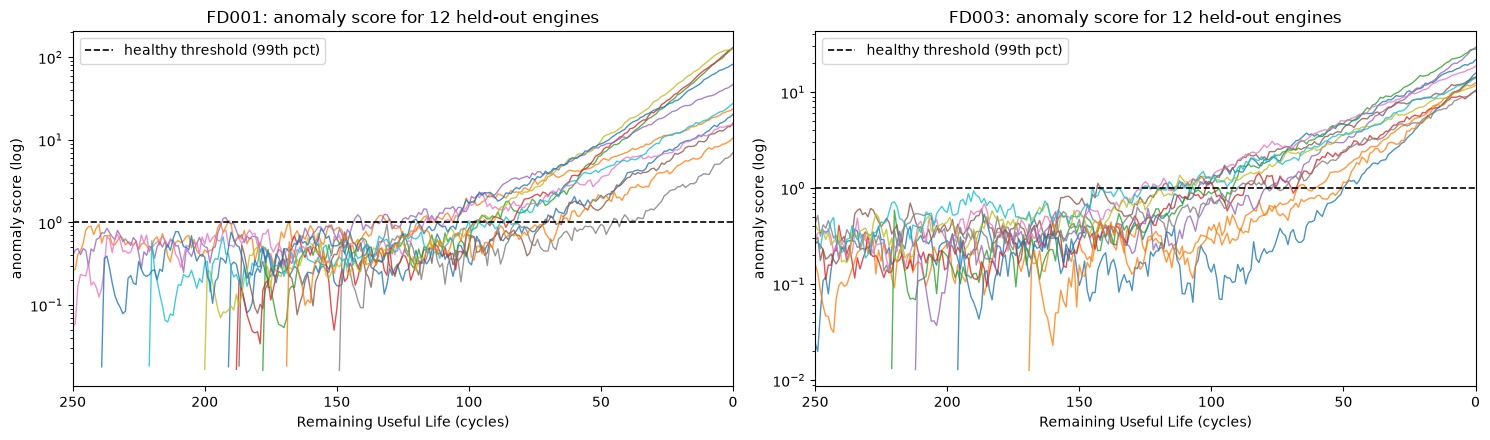

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, fd in zip(axes, ["FD001", "FD003"]):
    tr = pd.read_pickle(PROC / f"train_{fd}.pkl")
    m = tr[["unit", "RUL"]].join(oof_flags[fd][["anomaly_score", "alarm"]])
    for u in m["unit"].unique()[:12]:
        e = m[m["unit"] == u]
        ax.plot(e["RUL"], e["anomaly_score"], lw=1, alpha=0.8)
    ax.axhline(1.0, c="k", ls="--", lw=1.2, label="healthy threshold (99th pct)")
    ax.set_yscale("log"); ax.invert_xaxis(); ax.set_xlim(250, 0)
    ax.set_xlabel("Remaining Useful Life (cycles)"); ax.set_ylabel("anomaly score (log)")
    ax.set_title(f"{fd}: anomaly score for 12 held-out engines"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "08_anomaly_scores.png", bbox_inches="tight")
plt.show()

In [6]:
hm = joblib.load(MODELS / "health_monitor_FD003.joblib")
te = pd.read_pickle(PROC / "test_FD003.pkl")
ts = test_status[(test_status["subset"] == "FD003") & test_status["alarm"]].sort_values("pred_RUL")
for u in ts["unit"].head(3):
    row = te[te["unit"] == u].iloc[-1]
    r = ts[ts["unit"] == u].iloc[0]
    print(f"FD003 engine {u}: pred RUL {r.pred_RUL:.0f} (true {r.true_RUL}), score {r.anomaly_score:.1f}")
    for s, name, pct in hm.top_contributors(row):
        print(f"    {s:4s} {name:32s} {pct:5.1f}% of deviation")

FD003 engine 82: pred RUL 4 (true 6), score 9.2
    s12  Fuel flow / Ps30 ratio (phi)      49.4% of deviation
    s7   HPC outlet pressure (P30)         19.5% of deviation
    s11  HPC static pressure (Ps30)        16.9% of deviation
FD003 engine 94: pred RUL 7 (true 10), score 10.8
    s12  Fuel flow / Ps30 ratio (phi)      50.1% of deviation
    s7   HPC outlet pressure (P30)         21.2% of deviation
    s4   LPT outlet temperature (T50)       8.5% of deviation
FD003 engine 46: pred RUL 8 (true 7), score 9.5
    s12  Fuel flow / Ps30 ratio (phi)      49.5% of deviation
    s7   HPC outlet pressure (P30)         25.2% of deviation
    s11  HPC static pressure (Ps30)        16.8% of deviation
